In [1]:

# =====================================================
# PROJECT 4 — HEALTH INSURANCE CLAIMS INTELLIGENCE
# STEP 1: DATA DISCOVERY
# =====================================================

from pathlib import Path
import pandas as pd

# Find uploaded CSV files in Google Colab
csv_files = sorted(Path("/content").glob("*.csv"))

print("HEALTH INSURANCE — DATA DISCOVERY")
print("=" * 55)
print("CSV files found:", len(csv_files))

assert len(csv_files) > 0, "Please upload your CSV file first."

datasets = {}

for file in csv_files:
    df = pd.read_csv(file)
    datasets[file.stem] = df

    print(f"\nDATASET: {file.name}")
    print("-" * 55)
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Column names:", df.columns.tolist())
    print("Duplicate rows:", df.duplicated().sum())

    print("\nMissing values by column:")
    print(df.isna().sum().to_string())

    print("\nData types:")
    print(df.dtypes.to_string())

    print("\nFirst 3 rows:")
    display(df.head(3))

    # Inspect numeric columns
    print("\nNumeric summary:")
    display(df.describe().round(2))

print("\nDATA DISCOVERY COMPLETE")


HEALTH INSURANCE — DATA DISCOVERY
CSV files found: 2

DATASET: claims.csv
-------------------------------------------------------
Rows: 449
Columns: 9
Column names: ['claim_id', 'member_id', 'provider_id', 'claim_date', 'claim_type', 'cpt_code', 'icd_code', 'billed_amount', 'paid_amount']
Duplicate rows: 0

Missing values by column:
claim_id         0
member_id        0
provider_id      0
claim_date       0
claim_type       0
cpt_code         0
icd_code         0
billed_amount    0
paid_amount      0

Data types:
claim_id           int64
member_id          int64
provider_id       object
claim_date        object
claim_type        object
cpt_code          object
icd_code          object
billed_amount    float64
paid_amount      float64

First 3 rows:


,claim_id,member_id,provider_id,claim_date,claim_type,cpt_code,icd_code,billed_amount,paid_amount
0,1,1,PRV00001,3/12/2023,Outpatient,12345,A12.3,1800.0,1600.0
1,2,1,PRV00002,7/22/2023,Inpatient,67890,B99.4,32000.0,28000.0
2,3,1,PRV00003,1/15/2024,Lab,23456,C50.1,450.0,400.0



Numeric summary:


,claim_id,member_id,billed_amount,paid_amount
count,449.00,449.00,449.00,449.00
mean,236.01,51.65,4592.80,3453.77
std,134.40,29.34,6747.04,5040.67
min,1.00,1.00,60.00,0.00
25%,123.00,27.00,260.00,210.00
50%,240.00,52.00,1800.00,1280.00
75%,352.00,78.00,5400.00,4200.00
max,464.00,100.00,42000.00,35000.00



DATASET: members.csv
-------------------------------------------------------
Rows: 100
Columns: 6
Column names: ['member_id', 'member_age', 'member_gender', 'plan_type', 'enrollment_start_date', 'enrollment_end_date']
Duplicate rows: 0

Missing values by column:
member_id                 0
member_age                0
member_gender             0
plan_type                 0
enrollment_start_date     0
enrollment_end_date      15

Data types:
member_id                 int64
member_age                int64
member_gender            object
plan_type                object
enrollment_start_date    object
enrollment_end_date      object

First 3 rows:


,member_id,member_age,member_gender,plan_type,enrollment_start_date,enrollment_end_date
0,1,45,F,PPO,5/14/2021,11/30/2023
1,2,52,M,HMO,3/22/2020,8/15/2022
2,3,38,F,EPO,1/10/2022,4/1/2024



Numeric summary:


,member_id,member_age
count,100.00,100.00
mean,50.50,48.43
std,29.01,15.05
min,1.00,21.00
25%,25.75,38.00
50%,50.50,45.50
75%,75.25,58.00
max,100.00,94.00



DATA DISCOVERY COMPLETE


In [2]:

# ============================================================
# PROJECT 4 — HEALTH INSURANCE CLAIMS & COST INTELLIGENCE
# STEP 2: ANALYZE, VALIDATE, EXPORT FOR TABLEAU
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

# ------------------------------------------------------------
# 1. LOAD AND JOIN DATA
# ------------------------------------------------------------

claims = datasets["claims"].copy()
members = datasets["members"].copy()

# Each member must have one profile.
assert members["member_id"].is_unique, "Duplicate member IDs."
assert claims["claim_id"].is_unique, "Duplicate claim IDs."

df = claims.merge(
    members,
    on="member_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Check that every claim has a matching member.
assert (df["_merge"] == "both").all(), (
    "Some claims have no matching member."
)

df = df.drop(columns="_merge")

# Parse dates using the observed month/day/year format.
for column in [
    "claim_date",
    "enrollment_start_date",
    "enrollment_end_date"
]:
    df[column] = pd.to_datetime(
        df[column],
        format="%m/%d/%Y",
        errors="coerce"
    )

assert df["claim_date"].notna().all()
assert df["enrollment_start_date"].notna().all()
assert df["billed_amount"].ge(0).all()
assert df["paid_amount"].ge(0).all()

# Preserve identifier formatting for Tableau.
for column in ["cpt_code", "icd_code", "provider_id"]:
    df[column] = df[column].astype("string")

# Create useful dashboard date fields.
df["claim_year"] = df["claim_date"].dt.year
df["claim_month"] = df["claim_date"].dt.strftime("%Y-%m")

# Avoid division by zero.
df["claim_paid_ratio"] = np.where(
    df["billed_amount"] > 0,
    df["paid_amount"] / df["billed_amount"],
    np.nan
)

df["billed_minus_paid"] = (
    df["billed_amount"] - df["paid_amount"]
)

print("1. DATA QUALITY")
print("=" * 60)
print("Claims after join:", len(df))
print("Unique members:", df["member_id"].nunique())
print("Unique providers:", df["provider_id"].nunique())
print("Claim types:", sorted(df["claim_type"].unique()))
print("Zero-paid claims:", int(df["paid_amount"].eq(0).sum()))
print("Zero-billed claims:", int(df["billed_amount"].eq(0).sum()))
print(
    "Claims paid above billed:",
    int((df["paid_amount"] > df["billed_amount"]).sum())
)

# Enrollment-period audit; flag for review, do not exclude.
df["before_enrollment"] = (
    df["claim_date"] < df["enrollment_start_date"]
)
df["after_enrollment"] = (
    df["enrollment_end_date"].notna()
    & (df["claim_date"] > df["enrollment_end_date"])
)
df["outside_enrollment"] = (
    df["before_enrollment"] | df["after_enrollment"]
)

print(
    "Claims outside recorded enrollment dates:",
    int(df["outside_enrollment"].sum())
)

# ------------------------------------------------------------
# 2. EXECUTIVE KPI SUMMARY
# ------------------------------------------------------------

total_billed = df["billed_amount"].sum()
total_paid = df["paid_amount"].sum()
total_claims = len(df)
total_members = df["member_id"].nunique()

overall_paid_ratio = (
    total_paid / total_billed if total_billed > 0 else np.nan
)

print("\n2. EXECUTIVE SUMMARY")
print("=" * 60)
print(f"Total billed: ${total_billed:,.2f}")
print(f"Total paid: ${total_paid:,.2f}")
print(f"Total claims: {total_claims:,}")
print(f"Members with claims: {total_members:,}")
print(f"Overall paid ratio: {overall_paid_ratio:.2%}")
print(f"Average paid per claim: ${total_paid / total_claims:,.2f}")
print(f"Billed minus paid: ${total_billed - total_paid:,.2f}")

# ------------------------------------------------------------
# 3. REUSABLE COST SUMMARY FUNCTION
# ------------------------------------------------------------

def cost_summary(group_columns):
    """Create a spending summary for any grouping."""
    result = (
        df.groupby(group_columns, dropna=False)
        .agg(
            claim_count=("claim_id", "count"),
            total_billed=("billed_amount", "sum"),
            total_paid=("paid_amount", "sum"),
            avg_claim_paid_ratio=("claim_paid_ratio", "mean")
        )
        .reset_index()
    )

    result["avg_paid_per_claim"] = (
        result["total_paid"] / result["claim_count"]
    )

    result["weighted_paid_ratio"] = np.where(
        result["total_billed"] > 0,
        result["total_paid"] / result["total_billed"],
        np.nan
    )

    result["share_of_total_paid_pct"] = (
        result["total_paid"] / total_paid * 100
        if total_paid > 0 else np.nan
    )

    return result.sort_values(
        "total_paid", ascending=False
    ).reset_index(drop=True)

# ------------------------------------------------------------
# 4. CLAIM TYPE COST BREAKDOWN
# ------------------------------------------------------------

claim_type_summary = cost_summary(["claim_type"])

print("\n3. CLAIM TYPE SPENDING — RANKED")
display(claim_type_summary.round(2))

# ------------------------------------------------------------
# 5. TOP CPT AND ICD CODES
# ------------------------------------------------------------

cpt_summary = cost_summary(["cpt_code"])
icd_summary = cost_summary(["icd_code"])

top_10_cpt = cpt_summary.head(10)
top_10_icd = icd_summary.head(10)

# A minimum frequency helps distinguish repeatable cost
# patterns from a single unusually expensive claim.
high_avg_cpt = (
    cpt_summary[cpt_summary["claim_count"] >= 3]
    .sort_values("avg_paid_per_claim", ascending=False)
    .head(10)
)

print("\n4. TOP 10 CPT CODES BY TOTAL PAID")
display(top_10_cpt.round(2))

print("\n5. TOP 10 ICD CODES BY TOTAL PAID")
display(top_10_icd.round(2))

print("\n6. HIGH AVERAGE-COST CPT CODES (3+ CLAIMS)")
display(high_avg_cpt.round(2))

# ------------------------------------------------------------
# 6. HIGH-COST MEMBERS
# ------------------------------------------------------------

member_summary = cost_summary(["member_id"])

top_10_members = member_summary.head(10)

# Break down costs of the highest-cost members by claim type.
top_member_ids = top_10_members["member_id"].tolist()

member_claim_type = (
    df[df["member_id"].isin(top_member_ids)]
    .groupby(["member_id", "claim_type"], as_index=False)
    .agg(
        claim_count=("claim_id", "count"),
        total_paid=("paid_amount", "sum")
    )
    .sort_values(
        ["member_id", "total_paid"],
        ascending=[True, False]
    )
)

top_10_share = (
    top_10_members["total_paid"].sum() / total_paid * 100
    if total_paid > 0 else np.nan
)

print("\n7. TOP 10 HIGHEST-COST MEMBERS")
display(top_10_members.round(2))

print("\nTOP 10 MEMBERS — SPENDING SHARE")
print(f"Top 10 share of total paid: {top_10_share:.2f}%")

print("\n8. HIGH-COST MEMBER CLAIM TYPE BREAKDOWN")
display(member_claim_type.round(2))

# ------------------------------------------------------------
# 7. BILLED VS PAID BY PROVIDER AND CPT
# ------------------------------------------------------------

provider_summary = cost_summary(["provider_id"])

print("\n9. PAID RATIOS BY CLAIM TYPE")
display(
    claim_type_summary[
        [
            "claim_type",
            "claim_count",
            "total_billed",
            "total_paid",
            "avg_claim_paid_ratio",
            "weighted_paid_ratio"
        ]
    ].round(3)
)

print("\n10. PROVIDER SPENDING — TOP 10")
display(provider_summary.head(10).round(2))

print("\n11. CPT SPENDING AND PAID RATIOS — TOP 10")
display(top_10_cpt.round(3))

# Identify groups with unusually high paid-to-billed ratios.
# This is a screening measure, not proof of overpayment.
high_ratio_providers = (
    provider_summary[
        (provider_summary["claim_count"] >= 3)
        & (provider_summary["weighted_paid_ratio"] > 1)
    ]
)

print("\nPROVIDERS WITH PAID > BILLED (3+ CLAIMS)")
display(high_ratio_providers.round(3))

# ------------------------------------------------------------
# 8. CLAIMS SPENDING OVER TIME
# ------------------------------------------------------------

monthly_spending = (
    df.groupby("claim_month", as_index=False)
    .agg(
        claim_count=("claim_id", "count"),
        total_billed=("billed_amount", "sum"),
        total_paid=("paid_amount", "sum")
    )
    .sort_values("claim_month")
)

print("\n12. MONTHLY SPENDING")
display(monthly_spending.round(2))

# ------------------------------------------------------------
# 9. VALIDATION
# ------------------------------------------------------------

assert len(df) == len(claims)
assert claim_type_summary["claim_count"].sum() == len(df)
assert cpt_summary["claim_count"].sum() == len(df)
assert icd_summary["claim_count"].sum() == len(df)
assert member_summary["claim_count"].sum() == len(df)

assert np.isclose(
    claim_type_summary["total_paid"].sum(),
    total_paid
)
assert np.isclose(
    member_summary["total_paid"].sum(),
    total_paid
)
assert np.isclose(
    monthly_spending["total_paid"].sum(),
    total_paid
)

print("\n13. VALIDATION")
print("=" * 60)
print("Member join: PASS")
print("Claims reconciliation: PASS")
print("CPT and ICD reconciliation: PASS")
print("Member spending reconciliation: PASS")
print("Monthly spending reconciliation: PASS")

# ------------------------------------------------------------
# 10. EXPORT FOR TABLEAU
# ------------------------------------------------------------

# Main dashboard dataset: one row per claim.
# Includes member characteristics and claim measures.
output_files = {
    "health_claims_tableau_ready.csv": df,
    "claim_type_summary.csv": claim_type_summary,
    "cpt_summary.csv": cpt_summary,
    "icd_summary.csv": icd_summary,
    "member_summary.csv": member_summary,
    "provider_summary.csv": provider_summary,
    "monthly_spending.csv": monthly_spending
}

for filename, table in output_files.items():
    table.to_csv(
        Path("/content") / filename,
        index=False
    )

print("\n14. TABLEAU EXPORT")
print("=" * 60)
for filename, table in output_files.items():
    print(f"CREATED: {filename} — {len(table)} rows")

print("\nANALYSIS COMPLETE — READY FOR TABLEAU")


1. DATA QUALITY
Claims after join: 449
Unique members: 100
Unique providers: 103
Claim types: ['Emergency', 'Inpatient', 'Lab', 'Outpatient', 'Pharmacy']
Zero-paid claims: 2
Zero-billed claims: 0
Claims paid above billed: 0
Claims outside recorded enrollment dates: 266

2. EXECUTIVE SUMMARY
Total billed: $2,062,165.05
Total paid: $1,550,744.91
Total claims: 449
Members with claims: 100
Overall paid ratio: 75.20%
Average paid per claim: $3,453.77
Billed minus paid: $511,420.14

3. CLAIM TYPE SPENDING — RANKED


,claim_type,claim_count,total_billed,total_paid,avg_claim_paid_ratio,avg_paid_per_claim,weighted_paid_ratio,share_of_total_paid_pct
0,Inpatient,99,1478601.25,1092456.00,0.76,11034.91,0.74,70.45
1,Emergency,88,384241.55,294441.36,0.78,3345.92,0.77,18.99
2,Outpatient,105,160717.75,129052.75,0.84,1229.07,0.80,8.32
3,Lab,76,25789.90,23412.35,0.91,308.06,0.91,1.51
4,Pharmacy,81,12814.60,11382.45,0.89,140.52,0.89,0.73



4. TOP 10 CPT CODES BY TOTAL PAID


,cpt_code,claim_count,total_billed,total_paid,avg_claim_paid_ratio,avg_paid_per_claim,weighted_paid_ratio,share_of_total_paid_pct
0,67890,25,328030.00,242735.00,0.75,9709.40,0.74,15.65
1,23456,29,273380.75,203790.75,0.80,7027.27,0.75,13.14
2,00123,12,160280.00,122010.00,0.81,10167.50,0.76,7.87
3,12345,47,148262.00,115236.90,0.80,2451.85,0.78,7.43
4,99223,6,76500.00,57350.00,0.76,9558.33,0.75,3.70
5,34567,23,71555.00,54445.00,0.84,2367.17,0.76,3.51
6,45678,21,63456.25,52054.20,0.85,2478.77,0.82,3.36
7,00567,9,50230.00,38969.00,0.88,4329.89,0.78,2.51
8,54321,11,48430.00,36600.00,0.75,3327.27,0.76,2.36
9,56789,16,41390.00,33207.00,0.82,2075.44,0.80,2.14



5. TOP 10 ICD CODES BY TOTAL PAID


...


PROVIDERS WITH PAID > BILLED (3+ CLAIMS)


,provider_id,claim_count,total_billed,total_paid,avg_claim_paid_ratio,avg_paid_per_claim,weighted_paid_ratio,share_of_total_paid_pct



12. MONTHLY SPENDING


,claim_month,claim_count,total_billed,total_paid
0,2022-11,1,42000.00,31500.00
1,2023-01,2,34100.00,27400.00
2,2023-02,35,143671.00,113925.90
3,2023-03,67,337936.00,231064.50
4,2023-04,25,210815.00,170705.00
5,2023-05,37,362475.75,267075.60
6,2023-06,17,114230.50,72660.50
7,2023-07,38,215045.75,164840.75
8,2023-08,30,105546.50,88151.31
9,2023-09,23,52450.75,39215.25



13. VALIDATION
Member join: PASS
Claims reconciliation: PASS
CPT and ICD reconciliation: PASS
Member spending reconciliation: PASS
Monthly spending reconciliation: PASS

14. TABLEAU EXPORT
CREATED: health_claims_tableau_ready.csv — 449 rows
CREATED: claim_type_summary.csv — 5 rows
CREATED: cpt_summary.csv — 134 rows
CREATED: icd_summary.csv — 117 rows
CREATED: member_summary.csv — 100 rows
CREATED: provider_summary.csv — 103 rows
CREATED: monthly_spending.csv — 23 rows

ANALYSIS COMPLETE — READY FOR TABLEAU


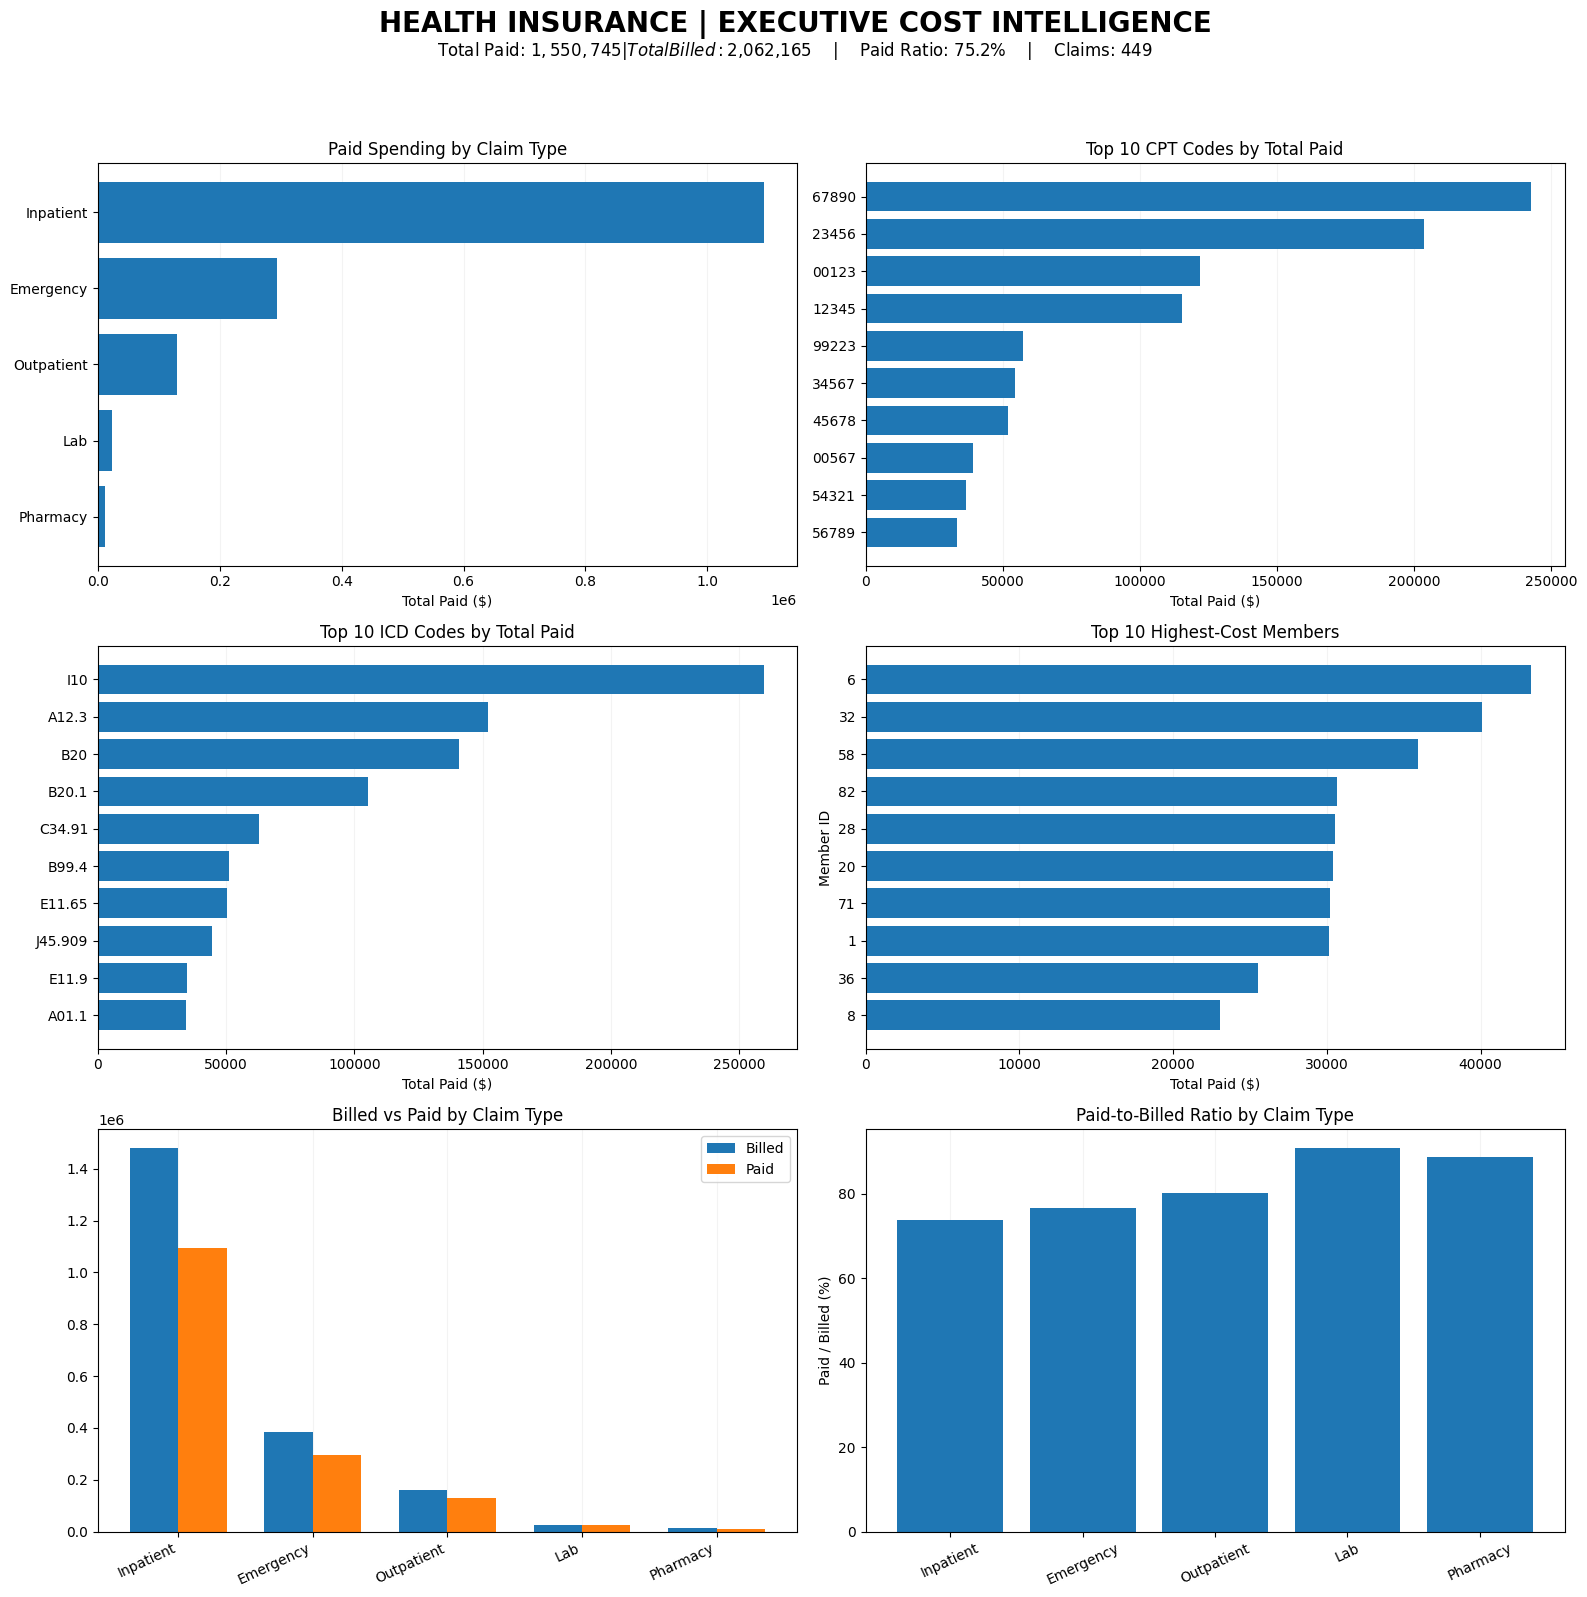


PROJECT 4 — FINAL STATUS
CREATED: executive_claims_dashboard.png
CREATED: RECOMMENDATIONS.md
CREATED: README.md
CREATED: requirements.txt
CREATED: .gitignore

READY FOR GITHUB PUBLICATION


In [3]:

# ============================================================
# PROJECT 4 — FINAL DASHBOARD + RECOMMENDATIONS + DOCUMENTATION
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

folder = Path("/content")

# These tables already exist from your successful analysis.
assert len(df) == 449, "Run the claims analysis cell first."
assert len(claim_type_summary) == 5
assert len(member_summary) == 100

# ------------------------------------------------------------
# 1. EXECUTIVE DASHBOARD
# ------------------------------------------------------------

fig, axes = plt.subplots(3, 2, figsize=(16, 16))
fig.suptitle(
    "HEALTH INSURANCE | EXECUTIVE COST INTELLIGENCE",
    fontsize=20, fontweight="bold", y=0.995
)

fig.text(
    0.5, 0.966,
    f"Total Paid: ${total_paid:,.0f}    |    "
    f"Total Billed: ${total_billed:,.0f}    |    "
    f"Paid Ratio: {overall_paid_ratio:.1%}    |    "
    f"Claims: {total_claims}",
    ha="center", fontsize=12
)

# Chart 1: claim types by paid spending
t = claim_type_summary.sort_values("total_paid")
axes[0, 0].barh(t["claim_type"], t["total_paid"])
axes[0, 0].set_title("Paid Spending by Claim Type")
axes[0, 0].set_xlabel("Total Paid ($)")

# Chart 2: top 10 CPT codes
t = top_10_cpt.sort_values("total_paid")
axes[0, 1].barh(t["cpt_code"].astype(str), t["total_paid"])
axes[0, 1].set_title("Top 10 CPT Codes by Total Paid")
axes[0, 1].set_xlabel("Total Paid ($)")

# Chart 3: top 10 ICD codes
t = top_10_icd.sort_values("total_paid")
axes[1, 0].barh(t["icd_code"].astype(str), t["total_paid"])
axes[1, 0].set_title("Top 10 ICD Codes by Total Paid")
axes[1, 0].set_xlabel("Total Paid ($)")

# Chart 4: highest-cost members
t = top_10_members.sort_values("total_paid")
axes[1, 1].barh(
    t["member_id"].astype(str), t["total_paid"]
)
axes[1, 1].set_title("Top 10 Highest-Cost Members")
axes[1, 1].set_xlabel("Total Paid ($)")
axes[1, 1].set_ylabel("Member ID")

# Chart 5: billed versus paid by claim type
t = claim_type_summary.sort_values(
    "total_paid", ascending=False
)
x = np.arange(len(t))
w = 0.36
axes[2, 0].bar(
    x - w/2, t["total_billed"], w, label="Billed"
)
axes[2, 0].bar(
    x + w/2, t["total_paid"], w, label="Paid"
)
axes[2, 0].set_xticks(x)
axes[2, 0].set_xticklabels(
    t["claim_type"], rotation=25, ha="right"
)
axes[2, 0].set_title("Billed vs Paid by Claim Type")
axes[2, 0].legend()

# Chart 6: weighted paid ratio by claim type
axes[2, 1].bar(
    t["claim_type"],
    t["weighted_paid_ratio"] * 100
)
axes[2, 1].set_title("Paid-to-Billed Ratio by Claim Type")
axes[2, 1].set_ylabel("Paid / Billed (%)")
axes[2, 1].tick_params(axis="x", rotation=25)

for ax in axes.flat:
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 0.95])

dashboard_path = folder / "executive_claims_dashboard.png"
plt.savefig(dashboard_path, dpi=180, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 2. DETAILED BUSINESS RECOMMENDATIONS
# ------------------------------------------------------------

recommendations = """# Business Recommendations & Improvement Opportunities

## Executive Summary

The insurer paid $1,550,744.91 across 449 claims,
against $2,062,165.05 in billed charges.

The overall paid-to-billed ratio was 75.20%.

Inpatient services account for 70.45% of total paid
spending and should be the first focus of cost review.

These figures do not establish company profitability.
Premium revenue, administrative expenses, and other
financial information are required to determine profit.

## 1. Prioritize Inpatient Cost Management

Priority: HIGH

Evidence:
99 inpatient claims account for $1,092,456 in payments,
representing 70.45% of all paid spending.

Recommended actions:
- Review inpatient claims for recurring high-cost services.
- Compare paid amounts for similar procedures and diagnoses.
- Examine hospital contracting and payment arrangements.
- Investigate opportunities to improve care coordination,
  clinical quality, and avoidable admissions.

KPIs:
- Inpatient paid amount per claim
- Inpatient spending share
- Risk-adjusted admission and readmission rates

Expected benefit:
Potential cost-management opportunities, subject to
clinical, contractual, and financial validation.

## 2. Review High-Spending CPT Procedures

Priority: HIGH

Evidence:
CPT 67890 accounts for $242,735 in payments (15.65%).
CPT 23456 accounts for $203,790.75 (13.14%).
CPT 00123 averages $10,167.50 per claim.

Recommended actions:
- Audit procedure coding and payment calculation accuracy.
- Compare amounts for clinically comparable services.
- Examine high-cost procedures for contract opportunities.
- Validate code meanings before clinical interpretation.

KPIs:
- Total paid per CPT
- Average paid per claim
- Procedure utilization trends
- Coding and payment exception rates

## 3. Investigate Major Diagnosis Cost Drivers

Priority: HIGH

Evidence:
ICD I10 accounts for $259,566 in payments (16.74%),
the largest total among observed diagnosis codes.

Recommended actions:
- Review costly diagnoses and associated procedures.
- Investigate appropriate preventive care and coordinated
  disease management programs.
- Evaluate whether spending patterns reflect severity,
  utilization, or higher prices.
- Confirm diagnosis coding consistency.

KPIs:
- Paid spending per diagnosis
- Utilization by diagnosis
- Risk-adjusted cost trends
- Avoidable utilization measures

## 4. Strengthen High-Cost Member Support

Priority: MEDIUM

Evidence:
The 10 highest-cost members account for 20.63%
of total paid spending.

Recommended actions:
- Analyze the service mix behind concentrated costs.
- Offer appropriate voluntary care coordination support.
- Look for clinically justified opportunities to prevent
  avoidable complications and duplicate services.
- Protect member confidentiality in dashboards and reviews.

KPIs:
- Cost concentration by member cohort
- Emergency and inpatient utilization
- Care coordination outcomes
- Member health and experience measures

Important:
High spending alone must not be treated as evidence
that a member is receiving unnecessary care.

## 5. Review Provider Spending and Payment Variability

Priority: HIGH

Evidence:
Provider PRV00002 accounts for $318,850 in paid claims,
or 20.56% of portfolio spending.

Recommended actions:
- Compare providers using similar service categories.
- Evaluate procedure mix, volume, and contractual rates.
- Review payment differences after accounting for case mix.
- Prioritize unusual patterns for routine financial review.

KPIs:
- Paid amount per comparable service
- Provider share of spending
- Contract payment accuracy
- Cost and quality outcomes

High provider spending is not proof of improper payment.

## 6. Improve Paid-Ratio Monitoring

Priority: MEDIUM

Evidence:
The overall paid-to-billed ratio is 75.20%.
Inpatient's weighted ratio is approximately 73.9%,
while Lab's is approximately 90.8%.

Recommended actions:
- Compare paid ratios at claim, category, and provider level.
- Review zero-paid claims and payment adjustments.
- Evaluate differences against contractual terms.
- Report both average claim-level and weighted ratios.

KPIs:
- Weighted paid ratio
- Payment exceptions
- Denial and adjustment trends
- Contract compliance

The $511,420.14 billed-versus-paid difference
is not insurer profit.

## 7. Resolve Enrollment Date Inconsistencies

Priority: CRITICAL

Evidence:
266 of 449 claims (59.24%) fall outside their members'
recorded enrollment dates.

Recommended actions:
- Confirm the meaning and reliability of enrollment dates.
- Verify whether historical eligibility files are complete.
- Review coverage rules and any permitted payment exceptions.
- Resolve data definitions before operational decisions.

KPIs:
- Claims with verified eligibility
- Enrollment-date exceptions resolved
- Eligibility data accuracy
- Audit completion rate

These records must not be labeled fraudulent or improperly
paid without investigation.

## Implementation Roadmap

Immediate:
- Investigate enrollment date inconsistencies.
- Review inpatient spending and top CPT/ICD codes.

Next 30 days:
- Perform provider and procedure-level payment reviews.
- Establish standardized spending KPIs.

Next 60-90 days:
- Pilot clinically appropriate care coordination.
- Review validated improvement opportunities and outcomes.

Ongoing:
- Monitor payment trends and data quality.
- Evaluate cost, care quality, and member experience together.

## Final Conclusion

The strongest initial opportunities are inpatient spending,
high-cost procedures, high-cost diagnoses, and provider
payment variability.

Enrollment-data quality requires urgent attention before
management relies on eligibility-based interpretations.

Any projected savings or profitability improvement must
be verified using premium revenue, contractual details,
clinical evidence, and implementation costs.
"""

(folder / "RECOMMENDATIONS.md").write_text(
    recommendations, encoding="utf-8"
)

# ------------------------------------------------------------
# 3. GITHUB README
# ------------------------------------------------------------

readme = """# Health Insurance Claims — Executive Cost Intelligence

## Overview

A Python business intelligence project analyzing synthetic
health insurance claims to identify major spending drivers.

## Executive KPIs

| Metric | Result |
|---|---:|
| Total Claims | 449 |
| Members With Claims | 100 |
| Total Billed | $2,062,165.05 |
| Total Paid | $1,550,744.91 |
| Overall Paid Ratio | 75.20% |
| Top 10 Members' Spending Share | 20.63% |
| Inpatient Share of Paid Spending | 70.45% |

## Executive Dashboard

![Executive Claims Dashboard](executive_claims_dashboard.png)

## Main Findings

- Inpatient claims drive $1,092,456 in paid costs.
- CPT 67890 leads procedure spending at $242,735.
- ICD I10 leads diagnosis spending at $259,566.
- Provider PRV00002 accounts for $318,850 in payments.
- The 10 highest-cost members account for 20.63% of payments.
- 266 claims have dates outside recorded member enrollment,
  requiring investigation before eligibility conclusions.

## Business Recommendations

See [Recommendations](RECOMMENDATIONS.md) for seven
prioritized improvement opportunities and a practical
implementation roadmap.

## Tools

- Python
- pandas
- NumPy
- Matplotlib
- Google Colab

The project includes a Python-generated executive dashboard.
Tableau-ready data is included for optional future work.
No Tableau dashboard is claimed in this release.

## How to Run

1. Open `Health_Insurance_Claims_Analysis.ipynb`.
2. Upload `claims.csv` and `members.csv` to Colab.
3. Execute the cells in order.
4. Inspect the charts and exported dashboard.

## Dataset

- `claims.csv`: 449 historical synthetic claim records.
- `members.csv`: 100 synthetic member profiles.

The claims and members datasets are joined on `member_id`.

## Limitations

- Claims spending is not the same as company profitability.
- Enrollment-date inconsistencies require investigation.
- The dataset may not represent complete time periods.
- High spending does not prove fraud or unnecessary care.
- Codes must be validated before clinical interpretation.
- Observed costs alone cannot demonstrate achievable savings.
"""

(folder / "README.md").write_text(
    readme, encoding="utf-8"
)

(folder / "requirements.txt").write_text(
    "pandas>=2.0,<4.0\n"
    "numpy>=1.24\n"
    "matplotlib>=3.7,<4.0\n",
    encoding="utf-8"
)

(folder / ".gitignore").write_text(
    "__pycache__/\n"
    ".ipynb_checkpoints/\n"
    ".DS_Store\n"
    ".venv/\n",
    encoding="utf-8"
)

print("\nPROJECT 4 — FINAL STATUS")
print("=" * 55)

for filename in [
    "executive_claims_dashboard.png",
    "RECOMMENDATIONS.md",
    "README.md",
    "requirements.txt",
    ".gitignore"
]:
    p = folder / filename
    assert p.exists()
    print("CREATED:", filename)

print("\nREADY FOR GITHUB PUBLICATION")


In [4]:

# ============================================================
# PROJECT 4 — COMPLETE GITHUB PACKAGE
# Restores missing files + creates a detailed README
# ============================================================

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import pandas as pd
import numpy as np

root = Path("/content")
root.mkdir(parents=True, exist_ok=True)

# 1. CONFIRM ANALYSIS IS AVAILABLE
required = [
    "df", "datasets", "claim_type_summary",
    "cpt_summary", "icd_summary",
    "member_summary", "provider_summary",
    "monthly_spending", "total_paid", "total_billed"
]

missing = [name for name in required if name not in globals()]
assert not missing, (
    "Rerun your earlier analysis cell first. Missing: "
    + ", ".join(missing)
)

assert len(df) == 449
assert len(datasets["claims"]) == 449
assert len(datasets["members"]) == 100

# 2. RESTORE ORIGINAL DATASETS AND ALL ANALYSIS EXPORTS
exports = {
    "claims.csv": datasets["claims"],
    "members.csv": datasets["members"],
    "health_claims_tableau_ready.csv": df,
    "claim_type_summary.csv": claim_type_summary,
    "cpt_summary.csv": cpt_summary,
    "icd_summary.csv": icd_summary,
    "member_summary.csv": member_summary,
    "provider_summary.csv": provider_summary,
    "monthly_spending.csv": monthly_spending
}

# Optional existing member/claim-type detail
if "member_claim_type" in globals():
    exports["member_claim_type_summary.csv"] = member_claim_type

for name, table in exports.items():
    table.to_csv(root / name, index=False)

# 3. CALCULATE DOCUMENTATION VALUES FROM DATA
n_claims = len(df)
n_members = df["member_id"].nunique()
n_providers = df["provider_id"].nunique()
paid_ratio = total_paid / total_billed
avg_paid = total_paid / n_claims
billed_gap = total_billed - total_paid
top_10_members = member_summary.head(10)
top_10_share = top_10_members["total_paid"].sum() / total_paid * 100
eligibility_flags = int(df["outside_enrollment"].sum())

def markdown_table(table, columns, money_columns=()):
    """Build a readable Markdown table from a DataFrame."""
    headers = list(columns.values())
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]
    for _, row in table.iterrows():
        cells = []
        for col in columns:
            value = row[col]
            if col in money_columns:
                cells.append(f"${value:,.2f}")
            elif col in ("claim_count", "member_id"):
                cells.append(str(int(value)))
            elif "ratio" in col:
                cells.append(f"{value:.1%}" if pd.notna(value) else "N/A")
            else:
                cells.append(str(value))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

claim_table = markdown_table(
    claim_type_summary,
    {
        "claim_type": "Claim type",
        "claim_count": "Claims",
        "total_paid": "Total paid",
        "weighted_paid_ratio": "Paid / billed"
    },
    money_columns=["total_paid"]
)

cpt_table = markdown_table(
    cpt_summary.head(10),
    {
        "cpt_code": "CPT code",
        "claim_count": "Claims",
        "total_paid": "Total paid",
        "avg_paid_per_claim": "Average paid / claim"
    },
    money_columns=["total_paid", "avg_paid_per_claim"]
)

icd_table = markdown_table(
    icd_summary.head(10),
    {
        "icd_code": "ICD code",
        "claim_count": "Claims",
        "total_paid": "Total paid"
    },
    money_columns=["total_paid"]
)

member_table = markdown_table(
    top_10_members,
    {
        "member_id": "Member ID",
        "claim_count": "Claims",
        "total_paid": "Total paid"
    },
    money_columns=["total_paid"]
)

provider_table = markdown_table(
    provider_summary.head(5),
    {
        "provider_id": "Provider ID",
        "claim_count": "Claims",
        "total_paid": "Total paid",
        "weighted_paid_ratio": "Paid / billed"
    },
    money_columns=["total_paid"]
)

# 4. FULL PORTFOLIO README
readme = f"""# Health Insurance Claims — Cost & Spending Intelligence

## Executive Overview

This project examines **synthetic health insurance claims**
to identify the services, procedure codes, diagnosis codes,
providers, and members responsible for the highest spending.

The analysis was prepared for a hypothetical insurer's
executive leadership team to help prioritize financial
investigations and operational improvement opportunities.

**Core question:** Where is claims spending concentrated,
and which areas deserve deeper financial and clinical review?

## Executive Dashboard

![Health Insurance Executive Dashboard](executive_claims_dashboard.png)

The dashboard is a static, Python-generated overview built
with Matplotlib. A separate Tableau-ready CSV is included
for future interactive dashboard development.

## Key Performance Indicators

| KPI | Value |
|---|---:|
| Total claims | {n_claims:,} |
| Members with claims | {n_members:,} |
| Providers | {n_providers:,} |
| Total billed charges | ${total_billed:,.2f} |
| Total insurer payments | ${total_paid:,.2f} |
| Overall paid-to-billed ratio | {paid_ratio:.2%} |
| Average paid amount per claim | ${avg_paid:,.2f} |
| Billed minus paid | ${billed_gap:,.2f} |
| Top 10 members' share of payments | {top_10_share:.2f}% |
| Claims flagged outside enrollment dates | {eligibility_flags:,} |

**Important:** Billed-minus-paid is not profit.
The dataset does not include premiums, operating expenses,
or other information required to calculate profitability.

## Business Questions

1. Which types of claims drive the most spending?
2. Which CPT procedure codes are the largest cost drivers?
3. Which ICD diagnosis codes account for the most payments?
4. Which members account for the greatest spending?
5. How do billed and paid amounts compare across services,
   providers, and procedures?

## Datasets

**claims.csv** — 449 claim records containing:

- Claim, member, and provider identifiers
- Claim date and claim type
- CPT procedure code and ICD diagnosis code
- Billed amount and paid amount

**members.csv** — 100 member profiles containing:

- Member identifier and demographic attributes
- Plan type
- Enrollment start date and enrollment end date

The datasets are joined using `member_id`, with multiple
claims allowed per member.

## Methodology

### 1. Import and Validate

- Load both CSV files with pandas.
- Inspect row counts, column types, duplicates, and nulls.
- Join claims to member records using a many-to-one merge.
- Parse claim and enrollment dates.
- Examine zero-paid claims, payments above charges,
  and claims dated outside recorded enrollment periods.

### 2. Calculate Business Metrics

**Total paid:** SUM(paid_amount)

**Total billed:** SUM(billed_amount)

**Paid ratio:** SUM(paid_amount) / SUM(billed_amount)

**Average paid per claim:** Total paid / Claim count

**Member spending share:** Member paid / Portfolio paid

Two ratio types are provided: aggregate paid-to-billed ratio
and the average of individual claim-level ratios. They
answer different questions and should not be confused.

### 3. Rank Cost Drivers

- Rank claim types by total paid.
- Rank CPT and ICD codes by total paid.
- Compare average cost per CPT claim, with a minimum
  of three claims for the displayed high-average list.
- Rank high-cost members and review their service mix.
- Examine provider spending and payment ratios.

## Findings — Claim Type Spending

{claim_table}

**Main observation:** Inpatient claims account for
**70.45%** of total paid spending despite representing
99 of 449 claims. This is the primary area for cost review.

Emergency claims are the second-largest category.

## Findings — Top 10 CPT Codes

{cpt_table}

CPT `67890` leads total procedure spending at $242,735.
CPT `00123` has a particularly high average paid amount
per claim among codes with at least three claims.

Code identifiers are retained as text to preserve
leading zeros. Their clinical descriptions have not
been independently verified.

## Findings — Top 10 ICD Codes

{icd_table}

ICD `I10` accounts for the highest total paid amount:
$259,566 across 34 claims.

Total spending reflects both frequency and cost per claim.
The highest-spending code is not necessarily the most
expensive code on a per-claim basis.

## Findings — Highest-Cost Members

{member_table}

The ten highest-cost members account for **{top_10_share:.2f}%**
of insurer payments.

See `member_claim_type_summary.csv` for their service-level
cost breakdown.

High medical spending does not demonstrate unnecessary care.
Any intervention should prioritize clinical appropriateness,
privacy, and member outcomes.

## Findings — Highest-Spending Providers

{provider_table}

Provider `PRV00002` is the largest observed provider-level
spending contributor, with $318,850 paid.

Provider comparisons require consideration of service mix,
contract terms, claim volume, and patient complexity.

## Billed vs Paid Analysis

Across the portfolio:

- Total billed: ${total_billed:,.2f}
- Total paid: ${total_paid:,.2f}
- Overall weighted paid ratio: {paid_ratio:.2%}
- Billed-minus-paid difference: ${billed_gap:,.2f}

Payment ratios vary across claim types.
A lower paid ratio does not automatically indicate favorable
profitability, and a higher ratio does not prove overpayment.

See `claim_type_summary.csv`, `provider_summary.csv`, and
`cpt_summary.csv` for detailed comparisons.

## Data Quality and Limitations

### Enrollment Date Warning

**{eligibility_flags} of {n_claims} claims** are dated outside
their members' recorded enrollment periods.

This is a major data-quality or eligibility-definition
issue requiring investigation before making coverage or
payment-compliance conclusions. These records are retained
in the analysis, not labeled fraudulent.

### Additional Limitations

- The data is synthetic and relatively small.
- The source spans November 2022 through November 2024,
  with uneven coverage across months.
- Claims may not represent all incurred services or
  complete reporting periods.
- No premium revenue or administrative costs are included.
- No adjustment for clinical complexity or provider case mix
  has been performed.
- CPT and ICD descriptions were not validated against
  an authoritative clinical code reference.
- High costs or unusual ratios do not by themselves
  establish fraud, waste, or inappropriate treatment.
- No verified savings estimates are presented.

## Prioritized Business Recommendations

A detailed seven-part management action plan is available
in [RECOMMENDATIONS.md](RECOMMENDATIONS.md).

The key priorities are:

1. Review inpatient claims and contracting opportunities.
2. Investigate leading CPT and ICD spending drivers.
3. Evaluate major providers using comparable services.
4. Support appropriate care coordination for high-cost members.
5. Monitor payment ratios and payment accuracy.
6. Investigate the substantial enrollment-date inconsistencies.
7. Track operational improvements alongside quality outcomes.

## Technology and Tools

- **Python:** Core analysis and dashboard creation
- **pandas:** Data loading, joins, aggregations
- **NumPy:** Calculations
- **Matplotlib:** Static executive dashboard
- **Google Colab:** Notebook execution
- **CSV:** Tableau-ready export for optional future work

**Scope note:** This release contains a Python dashboard,
not a completed interactive Tableau workbook.

## Files

```text
Health-Insurance-Claims-Cost-Intelligence/
├── Health_Insurance_Claims_Analysis.ipynb
├── claims.csv
├── members.csv
├── health_claims_tableau_ready.csv
├── claim_type_summary.csv
├── cpt_summary.csv
├── icd_summary.csv
├── member_summary.csv
├── member_claim_type_summary.csv
├── provider_summary.csv
├── monthly_spending.csv
├── executive_claims_dashboard.png
├── RECOMMENDATIONS.md
├── README.md
├── requirements.txt
└── .gitignore
```

## Reproduce the Analysis

1. Clone or download the repository.
2. Install the Python dependencies:

```bash
python -m pip install -r requirements.txt
```

3. Open `Health_Insurance_Claims_Analysis.ipynb` in
   Google Colab or a compatible Jupyter environment.
4. Upload `claims.csv` and `members.csv` into `/content`
   when running in Colab.
5. Run the notebook from top to bottom.
6. Review the validation results, summary tables,
   dashboard image, and recommendations.

The included analysis notebook is designed for Colab.
Local Jupyter users may need to adjust `/content` paths.

## Suggested Future Improvements

- Build an interactive Tableau executive dashboard.
- Add dynamic reporting-period and claim-type filters.
- Verify enrollment and eligibility history.
- Add premium, administrative, and contractual data to
  support real insurer profitability analysis.
- Introduce risk-adjusted provider benchmarking.
- Evaluate clinical and financial outcomes of any
  proposed interventions.

## Conclusion

Inpatient services dominate the observed spending profile,
while specific CPT codes, ICD codes, and providers contribute
substantial additional concentration.

The most urgent data-governance issue is the mismatch between
claim dates and recorded enrollment periods.

This project provides an evidence-based starting point for
leadership review, not proof of avoidable costs or
a production-ready healthcare financial decision system.
"""

(root / "README.md").write_text(
    readme, encoding="utf-8"
)

# 5. RECREATE ESSENTIAL CONFIGURATION FILES
(root / "requirements.txt").write_text(
    "pandas>=2.0,<4.0\n"
    "numpy>=1.24\n"
    "matplotlib>=3.7,<4.0\n",
    encoding="utf-8"
)

(root / ".gitignore").write_text(
    "__pycache__/\n"
    ".ipynb_checkpoints/\n"
    ".DS_Store\n"
    ".venv/\n",
    encoding="utf-8"
)

# 6. CHECK REQUIRED DOCUMENTS AND DASHBOARD
required_files = [
    "claims.csv",
    "members.csv",
    "health_claims_tableau_ready.csv",
    "claim_type_summary.csv",
    "cpt_summary.csv",
    "icd_summary.csv",
    "member_summary.csv",
    "provider_summary.csv",
    "monthly_spending.csv",
    "executive_claims_dashboard.png",
    "RECOMMENDATIONS.md",
    "README.md",
    "requirements.txt",
    ".gitignore"
]

assert all((root / f).exists() for f in required_files), (
    "Run the previous dashboard cell first if image "
    "or recommendations are missing."
)

# 7. PACKAGE EVERYTHING EXCEPT NOTEBOOK
zip_path = root / "Health_Insurance_Project4_Files.zip"

with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
    for filename in required_files:
        z.write(root / filename, arcname=filename)
    if (root / "member_claim_type_summary.csv").exists():
        z.write(
            root / "member_claim_type_summary.csv",
            arcname="member_claim_type_summary.csv"
        )

print("PROJECT 4 — COMPLETE PACKAGE")
print("=" * 55)
print("README length:", len(readme), "characters")
print("Files included in ZIP:")
with ZipFile(zip_path) as z:
    for filename in z.namelist():
        print("✓", filename)

print("\nPACKAGE READY — notebook exported separately")

# Download ZIP directly from Colab
from google.colab import files
files.download(str(zip_path))


PROJECT 4 — COMPLETE PACKAGE
README length: 10770 characters
Files included in ZIP:
✓ claims.csv
✓ members.csv
✓ health_claims_tableau_ready.csv
✓ claim_type_summary.csv
✓ cpt_summary.csv
✓ icd_summary.csv
✓ member_summary.csv
✓ provider_summary.csv
✓ monthly_spending.csv
✓ executive_claims_dashboard.png
✓ RECOMMENDATIONS.md
✓ README.md
✓ requirements.txt
✓ .gitignore
✓ member_claim_type_summary.csv

PACKAGE READY — notebook exported separately


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>